# Week 7b: PyTorch

The same network as notebook 07, now in **PyTorch**. First you'll check that `autograd` computes exactly the gradients you derived by hand. Then you'll use the real tools: `nn.Module`, loss functions, optimizers, the GPU, and regularisation.

Spec: `docs/superpowers/specs/2026-10-23-deep-learning-design.md`

## Setup (given)
The data from notebook 07, plus **the same starting weights** (same seed, same order), so the gradients can be compared number for number.

In [1]:
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch import nn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

sys.path.insert(0, '../service')
from clean import clean_description

df = pd.read_csv('../data/fake_transactions.csv')
df['Clean'] = df['Description'].fillna('').str.strip().apply(clean_description)
data = df[df['Clean'] != '']
text_train, text_test, cat_train, cat_test = train_test_split(
    data['Clean'], data['Category'], test_size=0.2, stratify=data['Category'], random_state=42)
vec = TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 4)).fit(text_train)
X_train, X_test = vec.transform(text_train).toarray(), vec.transform(text_test).toarray()
LABELS = sorted(data['Category'].unique())
y_train = np.array([LABELS.index(c) for c in cat_train])
y_test = np.array([LABELS.index(c) for c in cat_test])
N_IN, N_HIDDEN, N_OUT = X_train.shape[1], 64, len(LABELS)

# Notebook 07's starting weights: same rng, same order
rng = np.random.default_rng(0)
W1_np = rng.standard_normal((N_IN, N_HIDDEN)) * np.sqrt(2 / N_IN); b1_np = np.zeros(N_HIDDEN)
W2_np = rng.standard_normal((N_HIDDEN, N_OUT)) * np.sqrt(2 / N_HIDDEN); b2_np = np.zeros(N_OUT)
print(torch.__version__, '| GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none')

2.11.0+cu128 | GPU: NVIDIA GeForce RTX 3060 Laptop GPU


---
## A. Tensors and autograd
A tensor is a NumPy array that can remember how it was computed. With `requires_grad=True`, calling `loss.backward()` fills each tensor's `.grad`: backpropagation done for you.

1. Make tensors `W1, b1, W2, b2` from the `*_np` arrays (`torch.tensor(..., requires_grad=True)`; they stay float64)
2. `Xb, yb` = the first 32 rows of `X_train`, `y_train` as tensors
3. `logits = relu(Xb @ W1 + b1) @ W2 + b2`, then `loss = F.cross_entropy(logits, yb)`, then `loss.backward()`
4. Save `torch_grads = {'W1': W1.grad.numpy(), ...}` for all four

In [2]:
# TODO
# 1. Parameters as float64 tensors that track gradients
W1 = torch.tensor(W1_np, requires_grad=True)
b1 = torch.tensor(b1_np, requires_grad=True)
W2 = torch.tensor(W2_np, requires_grad=True)
b2 = torch.tensor(b2_np, requires_grad=True)

# 2. The first 32 rows, the same batch as notebook 07's gradient check
Xb = torch.tensor(X_train[:32])
yb = torch.tensor(y_train[:32])            # int64 class indices, not one-hot

# 3. Forward pass and backprop
logits = torch.relu(Xb @ W1 + b1) @ W2 + b2
loss = F.cross_entropy(logits, yb)         # softmax + cross-entropy in one, mean over rows
loss.backward()

# 4. Gradients as NumPy arrays
torch_grads = {'W1': W1.grad.numpy(), 'b1': b1.grad.numpy(),
               'W2': W2.grad.numpy(), 'b2': b2.grad.numpy()}

print(f'loss {loss.item():.4f}  dtype {W1.dtype}')
for k, g in torch_grads.items():
    print(f'{k}: {g.shape}')

loss 2.4294  dtype torch.float64
W1: (1337, 64)
b1: (64,)
W2: (64, 11)
b2: (11,)


This check (given) recomputes the gradients with notebook 07's backprop (written out here in NumPy) and compares them with autograd's.

In [3]:
def numpy_backprop(X, y):
    Z1 = X @ W1_np + b1_np; A1 = np.maximum(0, Z1); Z2 = A1 @ W2_np + b2_np
    P = np.exp(Z2 - Z2.max(1, keepdims=True)); P /= P.sum(1, keepdims=True)
    dZ2 = (P - np.eye(N_OUT)[y]) / len(y)
    dZ1 = (dZ2 @ W2_np.T) * (Z1 > 0)
    return {'W1': X.T @ dZ1, 'b1': dZ1.sum(0), 'W2': A1.T @ dZ2, 'b2': dZ2.sum(0)}

ours = numpy_backprop(X_train[:32], y_train[:32])
for k in ours:
    diff = np.abs(ours[k] - torch_grads[k]).max()
    print(f'{k}: max difference {diff:.1e}')
    assert diff < 1e-6, k
print('autograd matches your backprop ✓')

W1: max difference 1.7e-18
b1: max difference 4.2e-17
W2: max difference 2.6e-18
b2: max difference 4.2e-17
autograd matches your backprop ✓


---
## B. `nn.Module`
Real code doesn't create weights by hand. Build `model = nn.Sequential(nn.Linear(N_IN, N_HIDDEN), nn.ReLU(), nn.Linear(N_HIDDEN, N_OUT))`, use `loss_fn = nn.CrossEntropyLoss()` and `opt = torch.optim.SGD(model.parameters(), lr=0.5)`, and train 30 epochs with the given `train_epoch` helper. Print the test accuracy.

**Think:** `CrossEntropyLoss` takes the raw `logits`, not softmax probabilities. Why is it better for the loss to apply softmax itself? (Hint: `log(softmax(z))` of a very small probability.)

In [6]:
# Given helpers (float32 from here on, as real models use)
Xtr, ytr = torch.tensor(X_train, dtype=torch.float32), torch.tensor(y_train)
Xte, yte = torch.tensor(X_test, dtype=torch.float32), torch.tensor(y_test)

def train_epoch(model, opt, loss_fn, X, y, batch=64):
    """One pass over the data in shuffled mini-batches; returns the mean training loss."""
    model.train()
    total = 0.0
    for idx in torch.randperm(len(X)).split(batch):
        opt.zero_grad()
        loss = loss_fn(model(X[idx]), y[idx])
        loss.backward()
        opt.step()
        total += loss.item() * len(idx)
    return total / len(X)

@torch.no_grad()
def accuracy(model, X, y):
    model.eval()
    return float((model(X).argmax(1) == y).float().mean())

@torch.no_grad()
def val_loss(model, X, y):
    model.eval()
    return float(F.cross_entropy(model(X), y))

torch.manual_seed(0)

In [7]:
model = nn.Sequential(
    nn.Linear(N_IN, N_HIDDEN),
    nn.ReLU(),
    nn.Linear(N_HIDDEN, N_OUT),
)
loss_fn = nn.CrossEntropyLoss()
opt = torch.optim.SGD(model.parameters(), lr=0.5)

losses = [train_epoch(model, opt, loss_fn, Xtr, ytr) for _ in range(30)]

print(f'final train loss {losses[-1]:.3f}')
print(f'test accuracy: {accuracy(model, Xte, yte):.1%}  (notebook 07 NumPy: 98.6%)')

final train loss 0.083
test accuracy: 98.2%  (notebook 07 NumPy: 98.6%)


**Why logits:** If the loss gets softmax probabilities, a very wrong prediction has a tiny probability for the correct class, for example e^-200 ≈ 1e-87, which rounds to 0 in float32 (smallest ≈ 1e-45), so log(0) = -inf and the loss and gradients become inf/nan. Clipping with + 1e-12 avoids the crash but caps the loss at about 27.6, hiding how wrong the prediction is. Given raw logits, CrossEntropyLoss never computes that probability: it uses log(softmax(z))_i = z_i - log Σ exp(z), with the max subtracted first (log-sum-exp), so the log-probability (here -200) stays exact and finite, and the gradient is still the simple probs − Y.

---
## C. Optimizers: SGD vs Adam
Train two fresh models (call `torch.manual_seed(0)` before each, so they start the same) for 15 epochs: one with `SGD(lr=0.05)`, one with `Adam(lr=0.001)`. Keep each epoch's loss from `train_epoch` and plot both curves on one chart (log scale helps).

**Think:** Adam keeps a running average of each weight's gradients and their size. Why does that help it move faster early on?

SGD lr=0.05    final loss 1.795  test acc 39.9%
Adam lr=0.001  final loss 0.081  test acc 98.6%


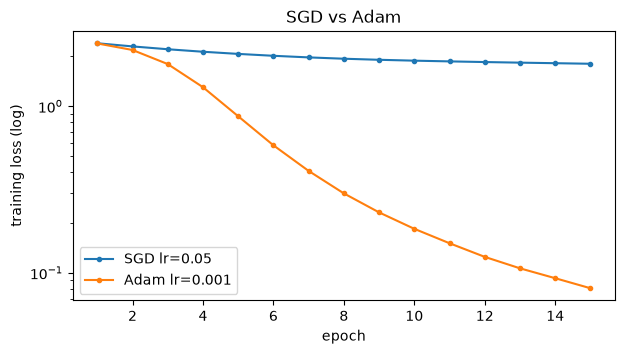

In [8]:
# TODO
def make_model():
    return nn.Sequential(nn.Linear(N_IN, N_HIDDEN), nn.ReLU(), nn.Linear(N_HIDDEN, N_OUT))

curves = {}
for name, make_opt in [('SGD lr=0.05',   lambda p: torch.optim.SGD(p, lr=0.05)),
                       ('Adam lr=0.001', lambda p: torch.optim.Adam(p, lr=0.001))]:
    torch.manual_seed(0)                       # same starting weights and shuffles
    m = make_model()
    opt = make_opt(m.parameters())
    curves[name] = [train_epoch(m, opt, nn.CrossEntropyLoss(), Xtr, ytr) for _ in range(15)]
    print(f'{name:14s} final loss {curves[name][-1]:.3f}  test acc {accuracy(m, Xte, yte):.1%}')

fig, ax = plt.subplots(figsize=(7, 3.5))
for name, c in curves.items():
    ax.plot(range(1, 16), c, marker='.', label=name)
ax.set(yscale='log', xlabel='epoch', ylabel='training loss (log)', title='SGD vs Adam')
ax.legend(); plt.show()

**Your answer:** After 15 epochs SGD (lr = 0.05) only got from about 2.4 to a loss of 1.795 (test accuracy 39.9%), while Adam (lr = 0.001, 50× smaller) reached 0.081 and 98.6%, the same accuracy the NumPy network needed 30 epochs at lr = 0.5 to reach. SGD's step is lr × gradient, so it depends on how big each gradient happens to be; here they're tiny (TF-IDF rows have unit length, and each n-gram weight only gets gradient from the few rows containing it), so most weights barely move. Adam keeps two running averages per weight: the mean gradient m (momentum, which smooths out batch noise so the weight keeps moving in a consistent direction) and the mean squared gradient v (its size). Its step is lr × m / √v, which cancels out the gradient's scale, so a weight with a small but consistent gradient still moves about lr per step. That's why Adam's curve bends down sharply from epoch 3 while SGD's stays almost flat.

---
## D. The GPU
`time_epoch(device)` (given) times one training epoch with the model and data on `'cpu'` or `'cuda'`. Call it for both.

In [11]:
def time_epoch(device, epochs=3):
    torch.manual_seed(0)
    model = nn.Sequential(nn.Linear(N_IN, N_HIDDEN), nn.ReLU(), nn.Linear(N_HIDDEN, N_OUT)).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=0.5)
    X, y = Xtr.to(device), ytr.to(device)
    train_epoch(model, opt, nn.CrossEntropyLoss(), X, y)          # warm-up
    if device == 'cuda': torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(epochs):
        train_epoch(model, opt, nn.CrossEntropyLoss(), X, y)
    if device == 'cuda': torch.cuda.synchronize()
    return round((time.perf_counter() - start) / epochs, 4)

In [12]:
# TODO
cpu_s = time_epoch('cpu')
gpu_s = time_epoch('cuda') if torch.cuda.is_available() else None

print(f'CPU : {cpu_s:.4f} s per epoch')
if gpu_s is not None:
    print(f'GPU : {gpu_s:.4f} s per epoch  →  {cpu_s / gpu_s:.1f}× ' +
          ('faster' if gpu_s < cpu_s else 'slower'))

CPU : 0.0124 s per epoch
GPU : 0.0274 s per epoch  →  0.5× slower


**Think:** for this tiny network the GPU may be **no faster**, or even slower. Why? (Hint: what does each mini-batch have to do besides maths, and how much maths is in a 64-row batch?) When would the GPU win easily?

**Your answer:** On this network the GPU was about 2.2× slower (0.0274 s vs 0.0124 s per epoch) because there's almost no maths to speed up. A 64-row batch is a (64 × 1337) @ (1337 × 64) and a (64 × 64) @ (64 × 11) multiply, about 11 million multiply-adds for the forward pass, which a CPU finishes in microseconds. But every batch also pays fixed costs that don't shrink with the model: each operation (matmul, ReLU, loss, every backward step, the optimizer update) is a separate GPU kernel launch costing a few microseconds; the shuffled index from torch.randperm is created on the CPU and copied to the GPU; and loss.item() makes the CPU wait for the GPU to finish after every batch. With only 18 batches of tiny work, that overhead is most of the time, so the GPU spends more time waiting than computing. The GPU wins easily when each batch has a lot of maths: big batches (thousands of rows), wide or deep layers (millions of weights), or models like CNNs and transformers. Then the thousands of GPU cores stay busy and the fixed cost per batch becomes negligible.

---
## E. Overfitting and regularisation
Overfitting is easier to see with little data, so train on only 60 rows (`Xtr_small`, given). Write `run(dropout, weight_decay, epochs=100)` that builds `Linear → ReLU → Dropout(dropout) → Linear`, trains with `AdamW(lr=0.01, weight_decay=weight_decay)`, and records the train loss and `val_loss` on the test set each epoch. Compare `run(0.0, 0.0)` with `run(0.5, 0.05)` side by side, and find the epoch where the plain run's validation loss was lowest (`idxmin()`).

In [13]:
Xtr_small, ytr_small = Xtr[:60], ytr[:60]

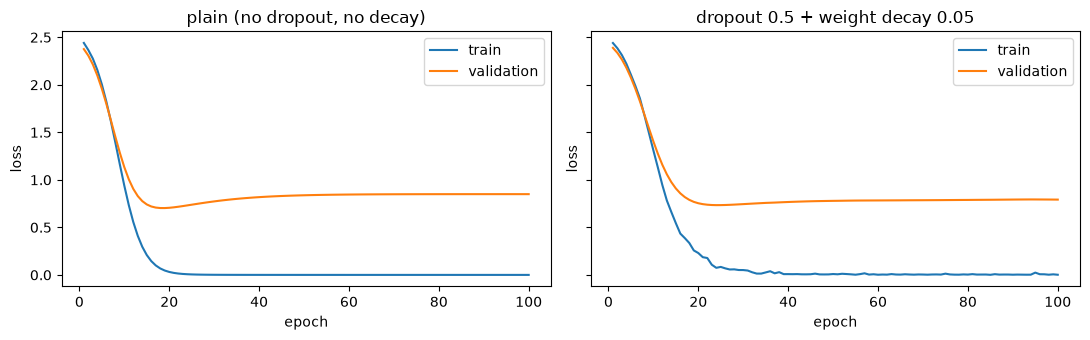

plain: lowest val loss 0.703 at epoch 19, final 0.850, final val acc 76.4%
reg  : lowest val loss 0.734 at epoch 24, final 0.792, final val acc 81.5%


In [14]:
# TODO
def run(dropout, weight_decay, epochs=100):
    torch.manual_seed(0)
    model = nn.Sequential(
        nn.Linear(N_IN, N_HIDDEN), nn.ReLU(),
        nn.Dropout(dropout),
        nn.Linear(N_HIDDEN, N_OUT),
    )
    opt = torch.optim.AdamW(model.parameters(), lr=0.01, weight_decay=weight_decay)
    loss_fn = nn.CrossEntropyLoss()
    rows = []
    for epoch in range(1, epochs + 1):
        tr = train_epoch(model, opt, loss_fn, Xtr_small, ytr_small)
        rows.append({'epoch': epoch, 'train': tr, 'val': val_loss(model, Xte, yte),
                     'val_acc': accuracy(model, Xte, yte)})
    return pd.DataFrame(rows).set_index('epoch')

plain = run(0.0, 0.0)
reg   = run(0.5, 0.05)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, (name, h) in zip(axes, [('plain (no dropout, no decay)', plain),
                                ('dropout 0.5 + weight decay 0.05', reg)]):
    ax.plot(h.index, h['train'], label='train')
    ax.plot(h.index, h['val'], label='validation')
    ax.set(title=name, xlabel='epoch', ylabel='loss')
    ax.legend()
plt.tight_layout(); plt.show()

best = plain['val'].idxmin()
print(f"plain: lowest val loss {plain['val'].min():.3f} at epoch {best}, "
      f"final {plain['val'].iloc[-1]:.3f}, final val acc {plain['val_acc'].iloc[-1]:.1%}")
print(f"reg  : lowest val loss {reg['val'].min():.3f} at epoch {reg['val'].idxmin()}, "
      f"final {reg['val'].iloc[-1]:.3f}, final val acc {reg['val_acc'].iloc[-1]:.1%}")

**Think:** in the plain run, what happens to the validation loss while the training loss keeps falling? What do dropout and weight decay each do to slow it down? And what is **early stopping**, and which epoch would it have picked here?

**Your answer:** In the plain run the training loss drops to about 0 by epoch 25 (60 rows are easy to memorise with ~86k weights), but the validation loss bottoms out at 0.703 at epoch 19 and then rises to 0.850 by epoch 100. After epoch 19 the network stops learning patterns that carry over to new descriptions and starts memorising the 60 training rows, becoming more and more confident in answers that are sometimes wrong on new data. That's overfitting.

Dropout (0.5) switches off a random half of the hidden units on every training step, so the network can't rely on any single unit or a specific combination of units to memorise a row; it has to spread what it learns across many units, which carries over better. Weight decay (0.05) shrinks every weight a little on each step, so weights only grow if the data keeps pushing them, which keeps the logits small and the predictions less overconfident. Together they slowed the overfitting: the regularised run's validation loss bottoms out a bit higher (0.734 at epoch 24) but then barely rises (0.792 at epoch 100 vs 0.850), and its final validation accuracy is 81.5% vs 76.4%. Its training loss is also noisier and slower to reach 0, because dropout keeps changing which units are used.

Early stopping means checking the validation loss after each epoch and keeping the weights from the epoch where it was lowest, instead of the last epoch. Here it would have picked epoch 19 for the plain run (val loss 0.703), before the network started memorising.

---
## F. Other architectures (concepts only)
You've built a **fully connected** network: every input connects to every hidden unit. Three other families matter, and interviewers ask about them:

- **CNN (convolutional network):** small filters (e.g. 3×3 pixels) slide across an image, and the *same* filter is reused everywhere. It finds an edge or an eye wherever it is, with far fewer weights than a fully connected layer.
- **RNN (recurrent network):** reads a sequence one step at a time (a letter, a word, a day of spending) and carries a *hidden state* forward, a memory of what it has seen so far.
- **LSTM:** an RNN with *gates* that decide what to keep, forget and output. Plain RNNs forget long-ago steps because the gradient shrinks a little at every step on the way back (the *vanishing gradient*); LSTMs keep a separate memory line that gradients can travel along.
- **Transformer:** no step-by-step reading. *Attention* lets every word look at every other word directly and decide which ones matter, all in parallel. That parallelism is why they train fast on GPUs and replaced RNNs for text. DistilBERT in notebook 09 is one.

Answer in your own words, 2–3 sentences each:

**1. Why does a CNN suit photos of receipts better than the fully connected network you built?**

**Your answer:** A receipt photo has millions of pixels, so a fully connected layer would need a separate weight for every pixel and every hidden unit, and it would have to learn the letter "T" again for every position where it might appear. A CNN slides the same small filters across the whole image, so one filter recognises an edge, a digit or a "₱" wherever it is on the receipt, with far fewer weights and much less data. It also respects the layout: nearby pixels are processed together, so strokes build up into characters and characters into lines of text.

**2. An RNN reads "JOLLIBEE*4821" one character at a time. What does its hidden state hold after the last character, and why would a plain RNN struggle with a very long description?**

**Your answer:** After the last character the hidden state is a compressed summary of the whole string: something like "started with JOLLIBEE, then a * and some digits", which is enough for the output layer to say Food & Drinks. A plain RNN struggles with a very long description because the gradient has to travel back through every character step and shrinks a little each time, so by the start of the string it is close to zero. The network can't learn that the early characters (often the merchant name) matter, and their information also fades from the hidden state as more characters overwrite it.

**3. How does a transformer read the same description differently, and why does that make it faster to train on a GPU?**

**Your answer:** A transformer takes all the characters or word pieces of "JOLLIBEE*4821" at once, and attention lets each one look directly at every other one, so "JOLLIBEE" can matter for the final prediction without its information having to survive 13 steps of memory. Since no position has to wait for the previous one, the whole sequence is processed as a few big matrix multiplications in parallel, which is exactly the kind of work a GPU is fast at, while an RNN has to go one step at a time.